# 01. Data preparation

Goal: turn the raw CTSSB-1M dataset (about 1M Python bug-fix commits) into a small, clean, leakage-free set of
`(buggy code, fixed code)` pairs: 4000 train / 500 val / 500 test.

Steps: load -> rebuild code from diff -> remove bad/duplicate pairs -> flag Python 2 -> split by project -> remove cross-split duplicates -> sample -> save -> plots.

All reusable logic lives in `src/data_utils.py`; this notebook only calls it and shows the numbers.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt

sys.path.append("../src")
import data_utils as du

RAW_DIR = Path("../data/raw/ctssb/ctssb_data_1M")
PROCESSED = Path("../data/processed")
FIGURES = Path("../results/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

SEED = 42
SAMPLE_SIZES = {"train": 4000, "val": 500, "test": 500}
funnel = {}  # how many pairs are left after each step

## Step 1. Load the raw shards and keep functions only

The dataset is split into 10 compressed files. We read them once, keep only the columns we need and keep only
`in_function == True` rows (the bug is inside a function, so the snippet is a meaningful unit of code).
The result is cached in `data/processed/pool.parquet`, so the next run takes seconds instead of minutes.

In [2]:
pool, n_raw = du.load_pool(RAW_DIR, PROCESSED / "pool.parquet")
funnel["raw_records"] = n_raw
funnel["in_function"] = len(pool)
print(f"raw records: {n_raw}, in_function: {len(pool)}")
print("all rows are likely bugs:", bool(pool["likely_bug"].all()))
pool.head(3)

reading shards:   0%|          | 0/10 [00:00<?, ?it/s]

raw records: 966985, in_function: 714241
all rows are likely bugs: True


,project,file_path,likely_bug,in_function,diff,sstub_pattern
0,trac,trac/util/tests/datefmt.py,True,True,"@@ -45,7 +45,7 @@ else:\n class DateFormatTest...",SINGLE_STMT
1,trac,trac/util/translation.py,True,True,"@@ -27,7 +27,7 @@ def gettext_noop(string, **k...",SINGLE_STMT
2,pyrollbar,rollbar/contrib/bottle/__init__.py,True,True,"@@ -12,7 +12,7 @@ class RollbarBottleReporter(...",CHANGE_ATTRIBUTE_USED


## Step 2. Rebuild buggy and fixed code from the diff

The dataset stores each fix as a git diff. In a diff a line starting with `-` exists only in the old (buggy) code,
`+` only in the new (fixed) code, and a space means the line is in both. From this we rebuild two full snippets.
We keep only diffs with exactly one hunk (one changed place), so each pair describes a single fix.

In [3]:
df = du.add_snippets(pool)
df = df[df["n_hunks"] == 1]
funnel["single_hunk"] = len(df)
print("pairs with a single hunk:", len(df))

row = df.iloc[0]
print("--- buggy ---")
print(row["buggy"])
print("--- fixed ---")
print(row["fixed"])

rebuilding code:   0%|          | 0/714241 [00:00<?, ?it/s]

pairs with a single hunk: 714241
--- buggy ---
class DateFormatTestCase(unittest.TestCase):

    def test_to_datetime(self):
        expected = datetime.datetime(1970,1,1,1,0,23,0,datefmt.localtz)
        self.assertEqual(datefmt.to_datetime(23), expected)
        self.assertEqual(datefmt.to_datetime(23L), expected)
        self.assertEqual(datefmt.to_datetime(23.0), expected)
--- fixed ---
class DateFormatTestCase(unittest.TestCase):

    def test_to_datetime(self):
        expected = datetime.datetime.fromtimestamp(23, datefmt.localtz)
        self.assertEqual(datefmt.to_datetime(23), expected)
        self.assertEqual(datefmt.to_datetime(23L), expected)
        self.assertEqual(datefmt.to_datetime(23.0), expected)


## Step 3. Remove fake fixes and duplicates

We hash every snippet after a light normalization (trailing spaces and blank lines are ignored, but **indentation is
kept**, because in Python indentation changes the meaning).

* If `buggy` and `fixed` have the same hash, the commit only changed formatting - not a real fix, so we drop it.
* If the same `(buggy, fixed)` pair appears several times (forks, copied code), we keep only the first one.

In [4]:
df = du.add_hashes(df)

df = df[df["buggy_hash"] != df["fixed_hash"]]
funnel["real_change"] = len(df)

df = df.drop_duplicates(["buggy_hash", "fixed_hash"], keep="first")
funnel["deduplicated"] = len(df)
print("real changes:", funnel["real_change"], "| after dedup:", funnel["deduplicated"])

real changes: 713790 | after dedup: 647850


## Step 4. Mark Python 2 code

Part of the dataset is old Python 2 code (`print "x"`, `except E, e:`, `10L` ...). We do **not** remove it, we only
add an `is_py2` flag, so later we can check how much it influences the results.

In [5]:
df = du.add_python2_flag(df)
print(f"Python 2 share: {df['is_py2'].mean():.1%}")

Python 2 share: 4.9%


## Step 5. Split into train / val / test by project

We split 80/10/10 so that **all pairs of one project go to the same split**. Code from one project looks alike;
if it were in both train and test, the model could score well just by recognizing the project, not by finding bugs.

In [6]:
df = df.reset_index(drop=True)
df["split"] = du.split_by_project(df, seed=SEED, val=0.1, test=0.1)
print(df["split"].value_counts())
print(df["split"].value_counts(normalize=True).round(3))

split
train    517301
test      66974
val       63575
Name: count, dtype: int64
split
train    0.798
test     0.103
val      0.098
Name: proportion, dtype: float64


## Step 6. Remove cross-split duplicates and check leakage

Different projects can still contain the same code. Any val/test pair whose buggy or fixed snippet already appears in
an earlier split (train, then val) is removed. Finally we check that no project and no snippet is shared between splits.

In [7]:
df, dropped = du.remove_cross_split_duplicates(df)
funnel["no_cross_split_duplicates"] = len(df)
print("dropped:", dropped)

leakage = du.check_leakage(df)
leakage

dropped: {'val': 74, 'test': 93}


{'train-val': {'shared_projects': 0, 'shared_snippets': 0},
 'train-test': {'shared_projects': 0, 'shared_snippets': 0},
 'val-test': {'shared_projects': 0, 'shared_snippets': 0}}

## Step 7. Sample 5000 pairs and save

The full pool has hundreds of thousands of pairs, which is too much for the experiments. We take a random sample of
4000 train / 500 val / 500 test (fixed seed, so it is reproducible) and save one file per split.

In [8]:
sample = du.sample_pairs(df, SAMPLE_SIZES, seed=SEED)
funnel["sampled"] = len(sample)

save_cols = [
    "project", "file_path", "sstub_pattern", "buggy", "fixed",
    "is_py2", "buggy_hash", "fixed_hash", "split",
]
for name in du.SPLITS:
    part = sample[sample["split"] == name][save_cols].reset_index(drop=True)
    part.to_parquet(PROCESSED / f"{name}.parquet", index=False)
    print(name, len(part))

sample_leakage = du.check_leakage(sample)
sample_leakage

train 4000
val 500
test 500


{'train-val': {'shared_projects': 0, 'shared_snippets': 0},
 'train-test': {'shared_projects': 0, 'shared_snippets': 0},
 'val-test': {'shared_projects': 0, 'shared_snippets': 0}}

## Step 8. Summary

Key numbers for the report, also saved to `results/summary.json`.

In [9]:
def split_table(data):
    return {
        name: {
            "pairs": int((data["split"] == name).sum()),
            "projects": int(data.loc[data["split"] == name, "project"].nunique()),
            "python2_share": round(float(data.loc[data["split"] == name, "is_py2"].mean()), 4),
        }
        for name in du.SPLITS
    }


summary = {
    "funnel": funnel,
    "pool_splits": split_table(df),
    "sample_splits": split_table(sample),
    "python2_share_pool": round(float(df["is_py2"].mean()), 4),
    "python2_share_sample": round(float(sample["is_py2"].mean()), 4),
    "dropped_cross_split_duplicates": dropped,
    "leakage_pool": leakage,
    "leakage_sample": sample_leakage,
}
Path("../results/summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "funnel": {
    "raw_records": 966985,
    "in_function": 714241,
    "single_hunk": 714241,
    "real_change": 713790,
    "deduplicated": 647850,
    "no_cross_split_duplicates": 647683,
    "sampled": 5000
  },
  "pool_splits": {
    "train": {
      "pairs": 517301,
      "projects": 106446,
      "python2_share": 0.049
    },
    "val": {
      "pairs": 63501,
      "projects": 13294,
      "python2_share": 0.0527
    },
    "test": {
      "pairs": 66881,
      "projects": 13299,
      "python2_share": 0.049
    }
  },
  "sample_splits": {
    "train": {
      "pairs": 4000,
      "projects": 3360,
      "python2_share": 0.053
    },
    "val": {
      "pairs": 500,
      "projects": 427,
      "python2_share": 0.054
    },
    "test": {
      "pairs": 500,
      "projects": 417,
      "python2_share": 0.036
    }
  },
  "python2_share_pool": 0.0494,
  "python2_share_sample": 0.0514,
  "dropped_cross_split_duplicates": {
    "val": 74,
    "test": 93
  },
  "leakage_pool": {


## EDA plots

1. Funnel: how many pairs survive each step.
2. Snippet length: how long the buggy code is (in whitespace-separated tokens).
3. Bug types (`sstub_pattern`): what kinds of fixes are in the sample.
4. Python 2 share per split.

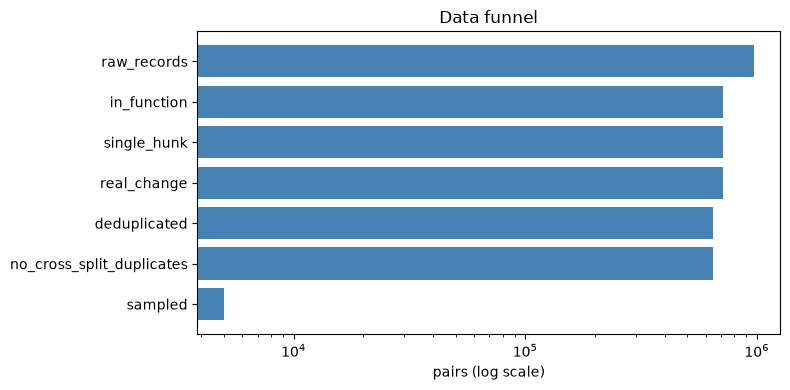

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(list(funnel)[::-1], list(funnel.values())[::-1], color="steelblue")
ax.set_xscale("log")
ax.set_xlabel("pairs (log scale)")
ax.set_title("Data funnel")
fig.tight_layout()
fig.savefig(FIGURES / "funnel.png", dpi=150)
plt.show()

count    5000.0
mean       22.7
std        12.0
min         2.0
25%        16.0
50%        21.0
75%        27.0
max       346.0
Name: buggy, dtype: float64


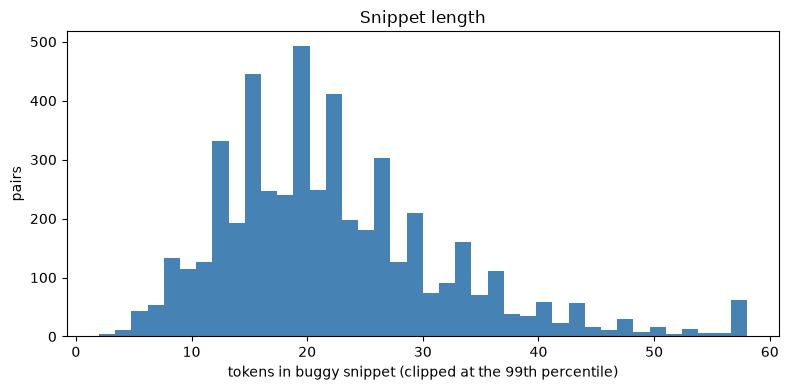

In [11]:
lengths = sample["buggy"].str.split().str.len()
print(lengths.describe().round(1))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(lengths.clip(upper=lengths.quantile(0.99)), bins=40, color="steelblue")
ax.set_xlabel("tokens in buggy snippet (clipped at the 99th percentile)")
ax.set_ylabel("pairs")
ax.set_title("Snippet length")
fig.tight_layout()
fig.savefig(FIGURES / "lengths.png", dpi=150)
plt.show()

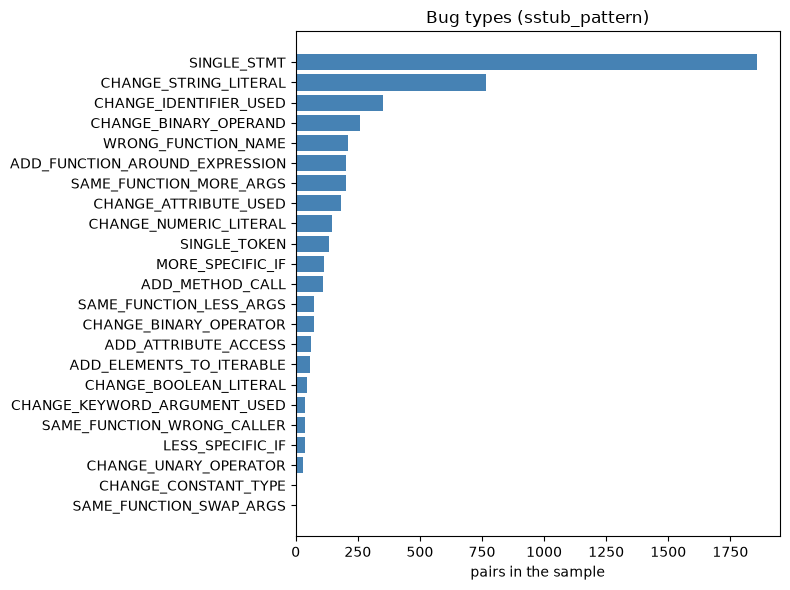

sstub_pattern
SINGLE_STMT               1857
CHANGE_STRING_LITERAL      767
CHANGE_IDENTIFIER_USED     350
CHANGE_BINARY_OPERAND      259
WRONG_FUNCTION_NAME        212
Name: count, dtype: int64

In [12]:
counts = sample["sstub_pattern"].value_counts()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(counts.index[::-1], counts.values[::-1], color="steelblue")
ax.set_xlabel("pairs in the sample")
ax.set_title("Bug types (sstub_pattern)")
fig.tight_layout()
fig.savefig(FIGURES / "sstub_pattern.png", dpi=150)
plt.show()
counts.head(5)

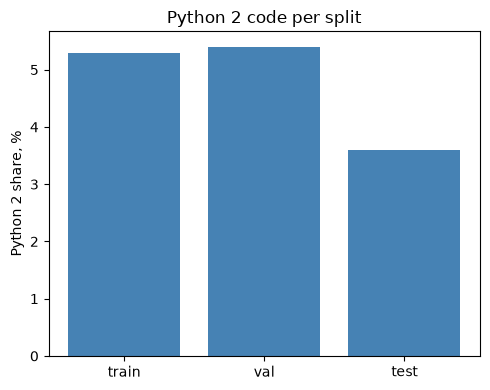

In [13]:
py2 = sample.groupby("split")["is_py2"].mean().reindex(du.SPLITS)
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(py2.index, py2.values * 100, color="steelblue")
ax.set_ylabel("Python 2 share, %")
ax.set_title("Python 2 code per split")
fig.tight_layout()
fig.savefig(FIGURES / "python2.png", dpi=150)
plt.show()